# Is the DD-Sudoku attention ceiling training-budget-limited? (900-epoch retrain)

**Run:** Slurm `48513926` (array 0-1), 2026-10-19. Output dir
`$SCRATCH/spin_gnn/sudoku_hparam_sweep_2026-10-19_ep900`.
Enrichment analyses: Slurm `48522086` (d=64), `48522087` (d=128).

**Git commit:** `6e3703c` (branch `sudoku-dd`), script
`scripts/slurm/sudoku2_long_train.sbatch`.

**Config** (identical to the 300-epoch runs except `epochs`):
`nhead=4, num_layers=12, dim_feedforward=1024, lr=1e-3, norm_first=True,
n_nodes=24, degree=5, n_colors=4, n_train_instances=5000,
n_val_instances=300, batch_size=32, n_per_bin=100, epochs=900`.
**Seeds:** `sudoku_hparam_sweep` defaults (single-seed runs; O(1) eval grid
uses eval seed start `20_000_000_000`, the attention analysis uses
`--seed-start 5000`). No seed variation was swept, so small differences
(<~0.03) should be read as within run-to-run noise.

## Hypotheses tested (one variable changed: epochs 300 -> 900)

**H1:** the attention-targeting enrichment plateau (~1.25x, flat from epoch
~75 per Slurm `48287024`) and the `agg_solve_rate=0.72` ceiling are
*training-budget*-limited -- `val_accuracy` was still slowly rising at epoch
300, so 3x the budget should raise `agg_solve_rate` and/or enrichment.

**H2:** `d_model=128`'s near-trivial regression at 300 epochs
(`mean_o1_solve_rate=0.896`, `solve_rate_k0=0.55`, vs `d_model=64`'s
`0.980/0.98`) was undertraining at larger width, not a capacity disadvantage
-- 900 epochs should recover it.

In [1]:
import pandas as pd
import numpy as np

rows = [
    # d_model, epochs, n_params, val_acc, val_nll, agg_solve_rate, mean_o1, k0, mean_enrichment, slurm
    (64,  300, 1806626, 0.5710, 1.2000, 0.7200, 0.980, 0.98, 1.255, "48162371 / 48267874"),
    (64,  900, 1806626, 0.5693, 1.3695, 0.7200, 0.984, 1.00, 1.246, "48513926_0 / 48522086"),
    (128, 300, 3994146, 0.5682, 1.6748, 0.7733, 0.896, 0.55, 1.249, "48446043_0 / 48449673"),
    (128, 900, 3994146, 0.5613, 2.1644, 0.7667, 0.968, 0.94, 1.129, "48513926_1 / 48522087"),
]
df = pd.DataFrame(rows, columns=[
    "d_model", "epochs", "n_params", "final_val_accuracy", "final_val_nll",
    "agg_solve_rate", "mean_o1_solve_rate", "solve_rate_k0", "mean_enrichment", "slurm",
])
df

,d_model,epochs,n_params,final_val_accuracy,final_val_nll,agg_solve_rate,mean_o1_solve_rate,solve_rate_k0,mean_enrichment,slurm
0,64,300,1806626,0.5710,1.2000,0.7200,0.980,0.98,1.255,48162371 / 48267874
1,64,900,1806626,0.5693,1.3695,0.7200,0.984,1.00,1.246,48513926_0 / 48522086
2,128,300,3994146,0.5682,1.6748,0.7733,0.896,0.55,1.249,48446043_0 / 48449673
3,128,900,3994146,0.5613,2.1644,0.7667,0.968,0.94,1.129,48513926_1 / 48522087


## Deltas: 900 epochs vs 300 epochs, same eval

In [2]:
for d in (64, 128):
    a = df[(df.d_model == d) & (df.epochs == 300)].iloc[0]
    b = df[(df.d_model == d) & (df.epochs == 900)].iloc[0]
    print(f"d_model={d}:")
    for col in ["agg_solve_rate", "mean_o1_solve_rate", "solve_rate_k0", "mean_enrichment", "final_val_nll", "final_val_accuracy"]:
        print(f"   {col:>20}: {a[col]:.4f} -> {b[col]:.4f}   (Δ{b[col]-a[col]:+.4f})")
    print()

d_model=64:
         agg_solve_rate: 0.7200 -> 0.7200   (Δ+0.0000)
     mean_o1_solve_rate: 0.9800 -> 0.9840   (Δ+0.0040)
          solve_rate_k0: 0.9800 -> 1.0000   (Δ+0.0200)
        mean_enrichment: 1.2550 -> 1.2460   (Δ-0.0090)
          final_val_nll: 1.2000 -> 1.3695   (Δ+0.1695)
     final_val_accuracy: 0.5710 -> 0.5693   (Δ-0.0017)

d_model=128:
         agg_solve_rate: 0.7733 -> 0.7667   (Δ-0.0066)
     mean_o1_solve_rate: 0.8960 -> 0.9680   (Δ+0.0720)
          solve_rate_k0: 0.5500 -> 0.9400   (Δ+0.3900)
        mean_enrichment: 1.2490 -> 1.1290   (Δ-0.1200)
          final_val_nll: 1.6748 -> 2.1644   (Δ+0.4896)
     final_val_accuracy: 0.5682 -> 0.5613   (Δ-0.0069)



### H1: **refuted.**
Tripling the budget bought nothing on the two metrics it was supposed to move.
`agg_solve_rate` is *identical* at `d_model=64` (0.7200 -> 0.7200) and
slightly down at `d_model=128` (0.7733 -> 0.7667, within noise). Enrichment is
flat at `d_model=64` (1.255 -> 1.246) and down at `d_model=128`
(1.249 -> 1.129). Meanwhile `final_val_nll` gets clearly *worse* in both
(1.20 -> 1.37, 1.67 -> 2.16) with `final_val_accuracy` flat -- the extra 600
epochs are spent overfitting the teacher-forced objective, not improving
either content-targeting or end-to-end solving. **The ceiling is real, not a
budget artifact.**

### H2: **confirmed.**
`d_model=128`'s near-trivial regression was undertraining: `mean_o1_solve_rate`
recovers 0.896 -> 0.968 and `solve_rate_k0` recovers 0.55 -> 0.94, both now
close to `d_model=64`'s 0.984/1.00. So the d_model sweep's "wider is worse on
easy cases" reading was a budget confound and should be retracted; what
survives is that `d_model=128` holds a small but real `agg_solve_rate`
advantage (0.767 vs 0.720, +0.047) *without* the easy-case deficit, while
still showing no enrichment gain.

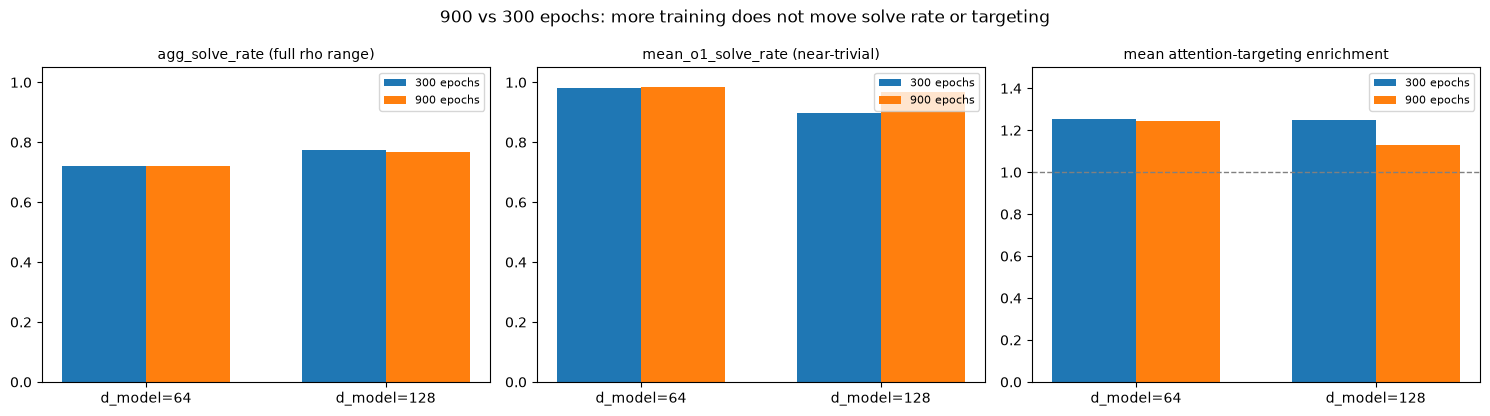

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics = [("agg_solve_rate", "agg_solve_rate (full rho range)"),
           ("mean_o1_solve_rate", "mean_o1_solve_rate (near-trivial)"),
           ("mean_enrichment", "mean attention-targeting enrichment")]
width = 0.35
for ax, (col, title) in zip(axes, metrics):
    for i, ep in enumerate((300, 900)):
        sub = df[df.epochs == ep].sort_values("d_model")
        ax.bar(np.arange(len(sub)) + i*width, sub[col], width, label=f"{ep} epochs")
    ax.set_xticks(np.arange(2) + width/2)
    ax.set_xticklabels(["d_model=64", "d_model=128"])
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    if col == "mean_enrichment":
        ax.axhline(1.0, color="gray", ls="--", lw=1)
        ax.set_ylim(0, 1.5)
    else:
        ax.set_ylim(0, 1.05)
fig.suptitle("900 vs 300 epochs: more training does not move solve rate or targeting", fontsize=12)
fig.tight_layout()
plt.show()

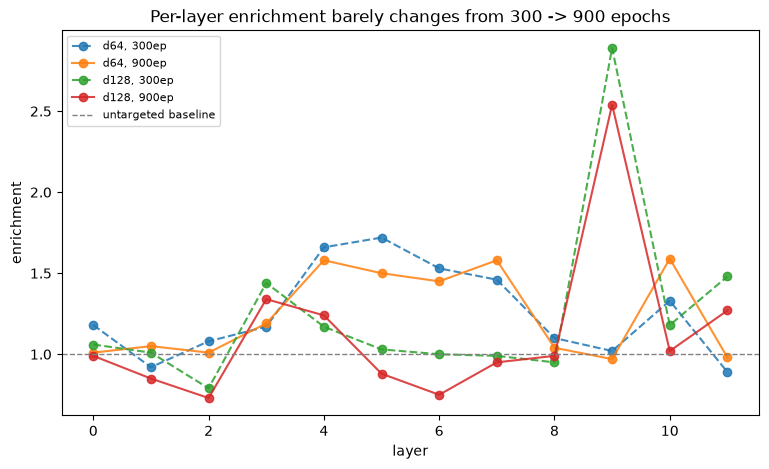

In [4]:
enrichment_by_layer = {
    "d64, 300ep":  [1.18, 0.92, 1.08, 1.17, 1.66, 1.72, 1.53, 1.46, 1.10, 1.02, 1.33, 0.89],
    "d64, 900ep":  [1.01, 1.05, 1.01, 1.19, 1.58, 1.50, 1.45, 1.58, 1.04, 0.97, 1.59, 0.98],
    "d128, 300ep": [1.06, 1.01, 0.79, 1.44, 1.17, 1.03, 1.00, 0.99, 0.95, 2.89, 1.18, 1.48],
    "d128, 900ep": [0.99, 0.85, 0.73, 1.34, 1.24, 0.88, 0.75, 0.95, 0.99, 2.54, 1.02, 1.27],
}
fig, ax = plt.subplots(figsize=(9, 5))
for label, vals in enrichment_by_layer.items():
    ls = "-" if "900" in label else "--"
    ax.plot(range(12), vals, "o", linestyle=ls, label=label, alpha=0.85)
ax.axhline(1.0, color="gray", ls="--", lw=1, label="untargeted baseline")
ax.set_xlabel("layer"); ax.set_ylabel("enrichment"); ax.legend(fontsize=8)
ax.set_title("Per-layer enrichment barely changes from 300 -> 900 epochs")
plt.show()

## Comparison to previous best, same eval

| config | epochs | agg_solve_rate | mean_o1_solve_rate | mean_enrichment |
|---|---|---|---|---|
| `d_model=64` (previous best, `48162371`) | 300 | 0.720 | **0.980** | 1.255 |
| `d_model=64` | 900 | 0.720 | **0.984** | 1.246 |
| `d_model=128` | 300 | 0.773 | 0.896 | 1.249 |
| `d_model=128` (**new best on agg**) | 900 | **0.767** | 0.968 | 1.129 |

`d_model=128 @ 900 epochs` is the best overall balance found so far:
`agg_solve_rate=0.767` (+0.047 over the previous best) with
`mean_o1_solve_rate=0.968` (-0.016, within noise of 0.980). That is a small
but eval-backed improvement on the full-rho metric. It is **not** an
improvement in attention targeting (enrichment 1.129, the lowest of the four).

## Net conclusion

Three architecture/budget levers have now been tested against the
content-targeting ceiling and **all three are negative**: more heads
(`48296020`), wider heads via larger `d_model` (`48446043`), and 3x training
budget (`48513926`). Enrichment sits at ~1.13-1.26x a distance-matched
baseline in every configuration tried, and `agg_solve_rate` is pinned near
0.72-0.77. The one thing longer training *did* buy was retracting the
d_model sweep's easy-case regression as a budget confound (H2).

Remaining untested idea: a change aimed at content-addressing itself (explicit
copy/pointer over node ids, or a relative/rotary positional scheme) rather
than more parameters or more steps.